**Лабораторная работа №4. Кластеризация**

**Цель работы:** изучение алгоритмов и методов кластеризации на практике: K-means, иерархическая агломеративная кластеризация, метрики качества кластеризации и выбор оптимального числа кластеров.

**Вариант №5** — набор данных `telecom_churn.csv` (информация о клиентах телеком-компании).

Работа состоит из двух частей:
- **Часть 1** — кластеризация синтетического набора данных, сформированного функцией `make_data`;
- **Часть 2** — кластеризация клиентов телеком-компании по варианту №5.

# Часть 1. Кластеризация синтетических данных

## 1. Формирование набора данных

Для получения набора данных использовалась функция `make_data(n, seed)`, формирующая три группы точек в двумерном пространстве со сдвигами `[3, 3]`, `[6, 9]`, `[9, 3]` и последующим масштабированием по осям. Параметр `n` задаёт число объектов в каждой группе, `seed` обеспечивает воспроизводимость. После генерации строки перемешиваются, поэтому истинные метки групп в набор не попадают.

Размер синтетического набора: (300, 2)


,x,y
0,180.939612,1.781485
1,192.283334,0.480938
2,162.443124,4.928830
3,70.851201,1.462777
4,194.350845,0.894492


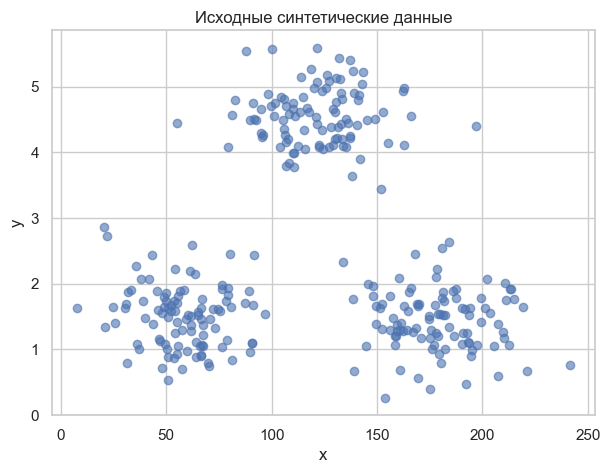

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn import metrics
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


def make_data(n, seed):
    np.random.seed(seed)
    shift_matrix = np.array([[3, 3], [6, 9], [9, 3]])
    data = np.random.randn(3, 2, n) + shift_matrix.reshape((3, 2, 1))
    data = np.swapaxes(data, 1, 2)
    data = data.reshape((-1, 2))
    data *= np.array([[20, 0.5]])
    df = pd.DataFrame({'x': data[:, 0], 'y': data[:, 1]}, columns=['x', 'y'])
    df = df.sample(frac=1.0, random_state=seed).reset_index(drop=True)
    return df


df_syn = make_data(n=100, seed=RANDOM_STATE)
print('Размер синтетического набора:', df_syn.shape)
display(df_syn.head())
plt.figure(figsize=(7, 5))
plt.scatter(df_syn['x'], df_syn['y'], alpha=0.6)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Исходные синтетические данные')
plt.show()

**Интерпретация.** На диаграмме рассеяния видны три достаточно обособленных облака точек: два вытянутых по оси `x` и одно с большим разбросом по `y`. Визуально структура соответствует трём группам, заложенным при генерации. При этом метки групп в набор не передавались, поэтому далее они восстанавливаются методами кластеризации.

## 2. Стандартизация данных

Поскольку K-means использует евклидово расстояние, признаки с большим масштабом начинают доминировать. Перед кластеризацией была выполнена стандартизация: каждый признак приведён к нулевому среднему и единичному стандартному отклонению.

In [24]:
scaler_syn = StandardScaler()
X_syn = scaler_syn.fit_transform(df_syn[['x', 'y']])
print('Средние после стандартизации:', np.round(X_syn.mean(axis=0), 6))
print('Стандартные отклонения после стандартизации:', np.round(X_syn.std(axis=0), 6))

Средние после стандартизации: [-0.  0.]
Стандартные отклонения после стандартизации: [1. 1.]


## 3. Кластеризация методом K-means (k = 3)

Модель K-means обучена на стандартизованных данных для трёх кластеров. Метки получены методом `fit_predict`, центры кластеров возвращены в исходный масштаб с помощью `inverse_transform`.

Метки кластеров (первые 20): [2 2 1 0 2 2 1 1 0 1 2 0 2 0 1 2 2 2 1 1]
Сумма квадратов расстояний: 70.669
Число итераций: 3
Размеры кластеров: [100 100 100]


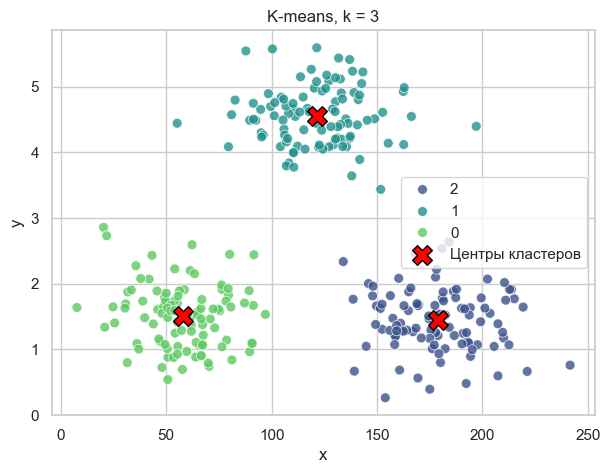

In [25]:
kmeans_syn = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
labels_syn = kmeans_syn.fit_predict(X_syn)
centers_syn = scaler_syn.inverse_transform(kmeans_syn.cluster_centers_)

print('Метки кластеров (первые 20):', labels_syn[:20])
print('Сумма квадратов расстояний:', round(kmeans_syn.inertia_, 3))
print('Число итераций:', kmeans_syn.n_iter_)
print('Размеры кластеров:', np.bincount(labels_syn))

plt.figure(figsize=(7, 5))
sns.scatterplot(x=df_syn['x'], y=df_syn['y'], hue=labels_syn.astype(str),
                palette='viridis', s=50, alpha=0.8)
plt.scatter(centers_syn[:, 0], centers_syn[:, 1], c='red', marker='X',
            s=200, edgecolor='black', label='Центры кластеров')
plt.xlabel('x')
plt.ylabel('y')
plt.title('K-means, k = 3')
plt.legend()
plt.show()

**Интерпретация.** Три кластера разделяют облака точек почти идеально: каждый кластер соответствует одной из трёх групп, заложенных при генерации. Красные маркеры центров расположены в центрах облаков. Компактность кластеров подтверждается высоким коэффициентом силуэта, который рассчитан ниже.

In [26]:
sil_syn = silhouette_score(X_syn, labels_syn)
print('Коэффициент силуэта для:', round(sil_syn, 4))

Коэффициент силуэта для: 0.7186


Коэффициент силуэта составил 0.719. Значение близко к единице, поэтому кластеры можно считать плотными и хорошо отделёнными друг от друга.

## 4. Сравнение результатов для k = 2, 3, 4

Для проверки устойчивости результата кластеризация была повторена для двух и четырёх кластеров. Для каждого варианта рассчитаны коэффициент силуэта и сумма квадратов расстояний, построены диаграммы рассеяния с центрами.

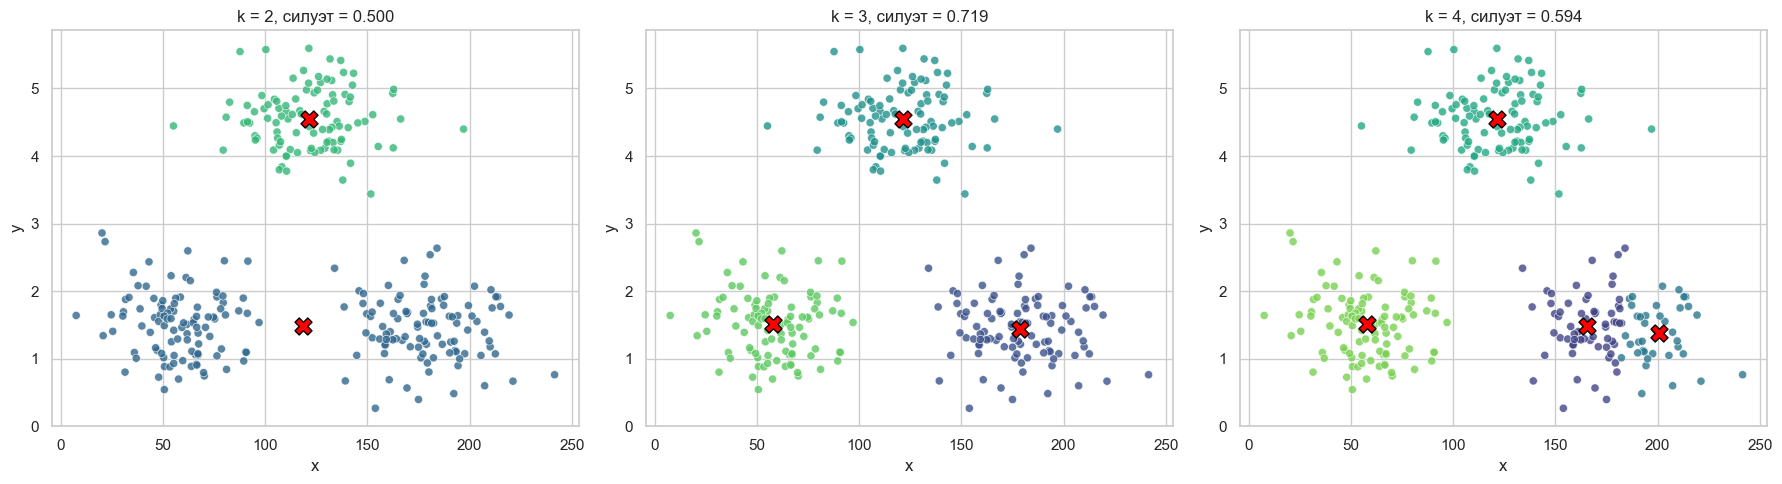

,k,inertia,silhouette
0,2,327.11,0.4997
1,3,70.67,0.7186
2,4,60.32,0.5938


In [27]:
results_syn = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, k in zip(axes, [2, 3, 4]):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X_syn)
    centers = scaler_syn.inverse_transform(model.cluster_centers_)
    sil = silhouette_score(X_syn, labels)
    results_syn.append({'k': k, 'inertia': model.inertia_, 'silhouette': sil})

    sns.scatterplot(x=df_syn['x'], y=df_syn['y'], hue=labels.astype(str),
                    palette='viridis', s=35, alpha=0.8, ax=ax, legend=False)
    ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='X',
               s=150, edgecolor='black')
    ax.set_title(f'k = {k}, силуэт = {sil:.3f}')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.tight_layout()
plt.show()

syn_table = pd.DataFrame(results_syn)
syn_table['inertia'] = syn_table['inertia'].round(2)
syn_table['silhouette'] = syn_table['silhouette'].round(4)
display(syn_table)

**Интерпретация.** При k = 2 два облака объединяются в один кластер, поэтому граница проходит не по естественным группам. При k = 4 одно из облаков дробится на две части, а сумма квадратов расстояний снижается незначительно. Наибольший коэффициент силуэта (0.719) достигается при k = 3, что согласуется с визуальной структурой данных. Значения для k = 2 (0.500) и k = 4 (0.594) заметно ниже.

## 5. Выбор числа кластеров методом локтя

Для диапазона k от 1 до 10 рассчитана сумма квадратов расстояний `inertia_`. На графике ищется точка, после которой снижение критерия замедляется.

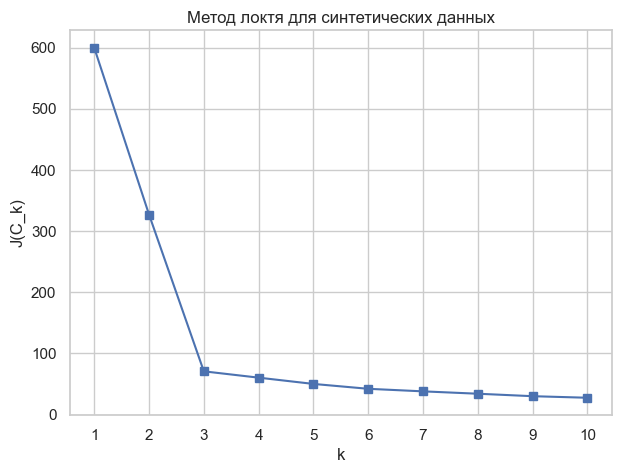

In [28]:
inertia_syn = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_syn)
    inertia_syn.append(model.inertia_)

plt.figure(figsize=(7, 5))
plt.plot(range(1, 11), inertia_syn, marker='s')
plt.xlabel('k')
plt.ylabel('J(C_k)')
plt.title('Метод локтя для синтетических данных')
plt.xticks(range(1, 11))
plt.show()

**Интерпретация.** На графике резкое снижение критерия происходит при переходе от k = 1 к k = 3, после чего кривая выполаживается. Наиболее выраженный излом соответствует k = 3: дальнейшее увеличение числа кластеров даёт небольшой выигрыш. Это подтверждает выбор трёх кластеров.

## 6. Выводы по Части 1

Синтетический набор содержит три хорошо разделимых группы. Метод K-means при k = 3 восстановил эту структуру: коэффициент силуэта составил 0.719, а центры кластеров совпали с центрами облаков. При k = 2 две группы объединяются, при k = 4 одна из групп дробится, и качество кластеризации снижается. Метод локтя также указывает на k = 3. Это подтверждает, что для данных с явно выраженной структурой K-means и коэффициент силуэта дают согласованный результат.

# Часть 2. Кластеризация клиентов телеком-компании (вариант №5)

## 1. Описание набора данных

Использован набор `telecom_churn.csv`, содержащий информацию о клиентах телеком-компании. Признаки: `age` — возраст; `gender` — пол; `contract_type` — тип контракта; `payment_method` — способ оплаты; `tenure_months` — стаж обслуживания; `monthly_charges` — ежемесячные платежи; `total_charges` — накопленные платежи; `avg_call_minutes` — среднее число минут звонков; `num_support_tickets` — число обращений в поддержку; `has_international_plan` — наличие международного плана; `region` — регион. Целевая переменная `Churn` принимает значение 1, если клиент ушёл, и 0, если остался.

## 2. Загрузка данных и первичный анализ

In [29]:
df = pd.read_csv('telecom_churn.csv')
print('Размер набора данных:', df.shape)
display(df.head())
display(df.describe().T)
print('Пропуски по столбцам:')
print(df.isna().sum())
print('Число полных дубликатов:', df.duplicated().sum())
print('Распределение целевой переменной Churn:')
print(df['Churn'].value_counts())
print('Доля ушедших клиентов:', round(df['Churn'].mean(), 4))

Размер набора данных: (3016, 12)


,age,gender,contract_type,payment_method,tenure_months,monthly_charges,total_charges,avg_call_minutes,num_support_tickets,has_international_plan,region,Churn
0,53,M,Month-to-month,Bank transfer,58,56.46,3448.16,206.9,0,No,North,0
1,18,F,Month-to-month,Electronic check,16,64.86,1227.48,345.3,2,Yes,West,1
2,81,M,Month-to-month,Electronic check,59,97.64,5773.27,242.8,0,No,North,0
3,65,F,One year,Credit card,16,27.90,416.11,257.2,0,Yes,North,0
4,40,F,Month-to-month,Electronic check,65,56.33,3805.53,205.1,1,No,North,0


,count,mean,std,min,25%,50%,75%,max
age,3016.0,51.519231,19.202550,18.00,35.7500,51.000,68.0000,84.000
tenure_months,3016.0,37.021220,21.228354,0.00,19.0000,37.000,55.0000,74.000
monthly_charges,3016.0,67.878336,26.120795,5.00,50.5575,67.170,84.8700,222.034
total_charges,3016.0,2499.773856,1797.004026,-84.31,1048.6300,2194.135,3677.9675,11620.220
avg_call_minutes,3016.0,249.071320,78.856929,20.00,196.4500,247.600,303.1000,499.600
num_support_tickets,3016.0,0.906830,1.016745,0.00,0.0000,1.000,1.0000,6.000
Churn,3016.0,0.159483,0.366186,0.00,0.0000,0.000,0.0000,1.000


Пропуски по столбцам:
age                       0
gender                    0
contract_type             0
payment_method            0
tenure_months             0
monthly_charges           0
total_charges             0
avg_call_minutes          0
num_support_tickets       0
has_international_plan    0
region                    0
Churn                     0
dtype: int64
Число полных дубликатов: 0
Распределение целевой переменной Churn:
Churn
0    2535
1     481
Name: count, dtype: int64
Доля ушедших клиентов: 0.1595


**Интерпретация.** Набор содержит 3016 наблюдений и 12 столбцов, пропусков и полных дубликатов нет. Целевая переменная несбалансирована: ушедшие клиенты составляют около 15.9% (481 наблюдение), оставшиеся — около 84.1% (2535 наблюдений). Числовые признаки имеют разный масштаб: например, `monthly_charges` изменяется примерно от 5 до 222, а `total_charges` — до 11620. Обнаружены 26 отрицательных значений `total_charges`; они встречаются только у клиентов с минимальным стажем (0–8 месяцев) и являются аномальными, поэтому были пересчитаны как `monthly_charges × tenure_months`.

## 3. Предварительная обработка данных

Отрицательные значения `total_charges` пересчитаны как `monthly_charges × tenure_months`: они появляются только у клиентов с минимальным стажем, поэтому восстановление по формуле приводит накопленные платежи в соответствие со стажем и ежемесячным платежом. Категориальные признаки закодированы прямым кодированием (`pd.get_dummies`, `drop_first=False`), чтобы не вводить искусственный порядок между категориями. Числовые признаки стандартизованы, а бинарные столбцы оставлены в масштабе 0/1, чтобы не увеличивать их вес в евклидовом расстоянии искусственно. Целевая переменная `Churn` в матрицу признаков не включалась.

In [30]:
df_model = df.copy()
negative_total = df_model['total_charges'] < 0
print('Число отрицательных значений total_charges до обработки:', int(negative_total.sum()))
recalc_total = (df_model.loc[negative_total, 'monthly_charges'] * df_model.loc[negative_total, 'tenure_months'])
df_model.loc[negative_total, 'total_charges'] = recalc_total
print('Диапазон восстановленных значений:', round(recalc_total.min(), 2), '-', round(recalc_total.max(), 2))

y = df_model['Churn']
X = df_model.drop('Churn', axis=1)

num_cols = ['age', 'tenure_months', 'monthly_charges', 'total_charges',
            'avg_call_minutes', 'num_support_tickets']
cat_cols = ['gender', 'contract_type', 'payment_method',
            'has_international_plan', 'region']

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=False)
X_scaled = X_encoded.copy()
scaler = StandardScaler()
X_scaled[num_cols] = scaler.fit_transform(X_encoded[num_cols])
X_scaled = X_scaled.astype(float).values

print('Размер матрицы признаков после кодирования:', X_encoded.shape)
print('Размер матрицы для кластеризации:', X_scaled.shape)
print('Число числовых признаков:', len(num_cols))
print('Число бинарных признаков после кодирования:', X_encoded.shape[1] - len(num_cols))

Число отрицательных значений total_charges до обработки: 26
Диапазон восстановленных значений: 0.0 - 273.81
Размер матрицы признаков после кодирования: (3016, 22)
Размер матрицы для кластеризации: (3016, 22)
Число числовых признаков: 6
Число бинарных признаков после кодирования: 16


**Интерпретация.** После кодирования матрица признаков содержит 22 столбца: 6 числовых и 16 бинарных. Целевая переменная в модель не входила. Стандартизация числовых признаков устраняет влияние масштаба, а бинарные признаки сохраняют исходный вид. Такая подготовка позволяет корректно применять метрики расстояния и не искажает веса категориальных признаков.

## 4. Матрица диаграмм рассеяния с выделением целевой переменной

Для визуальной оценки структуры данных построена матрица диаграмм рассеяния числовых признаков. Точки окрашены по значению целевой переменной `Churn`: ушедшие клиенты выделены отдельным цветом.

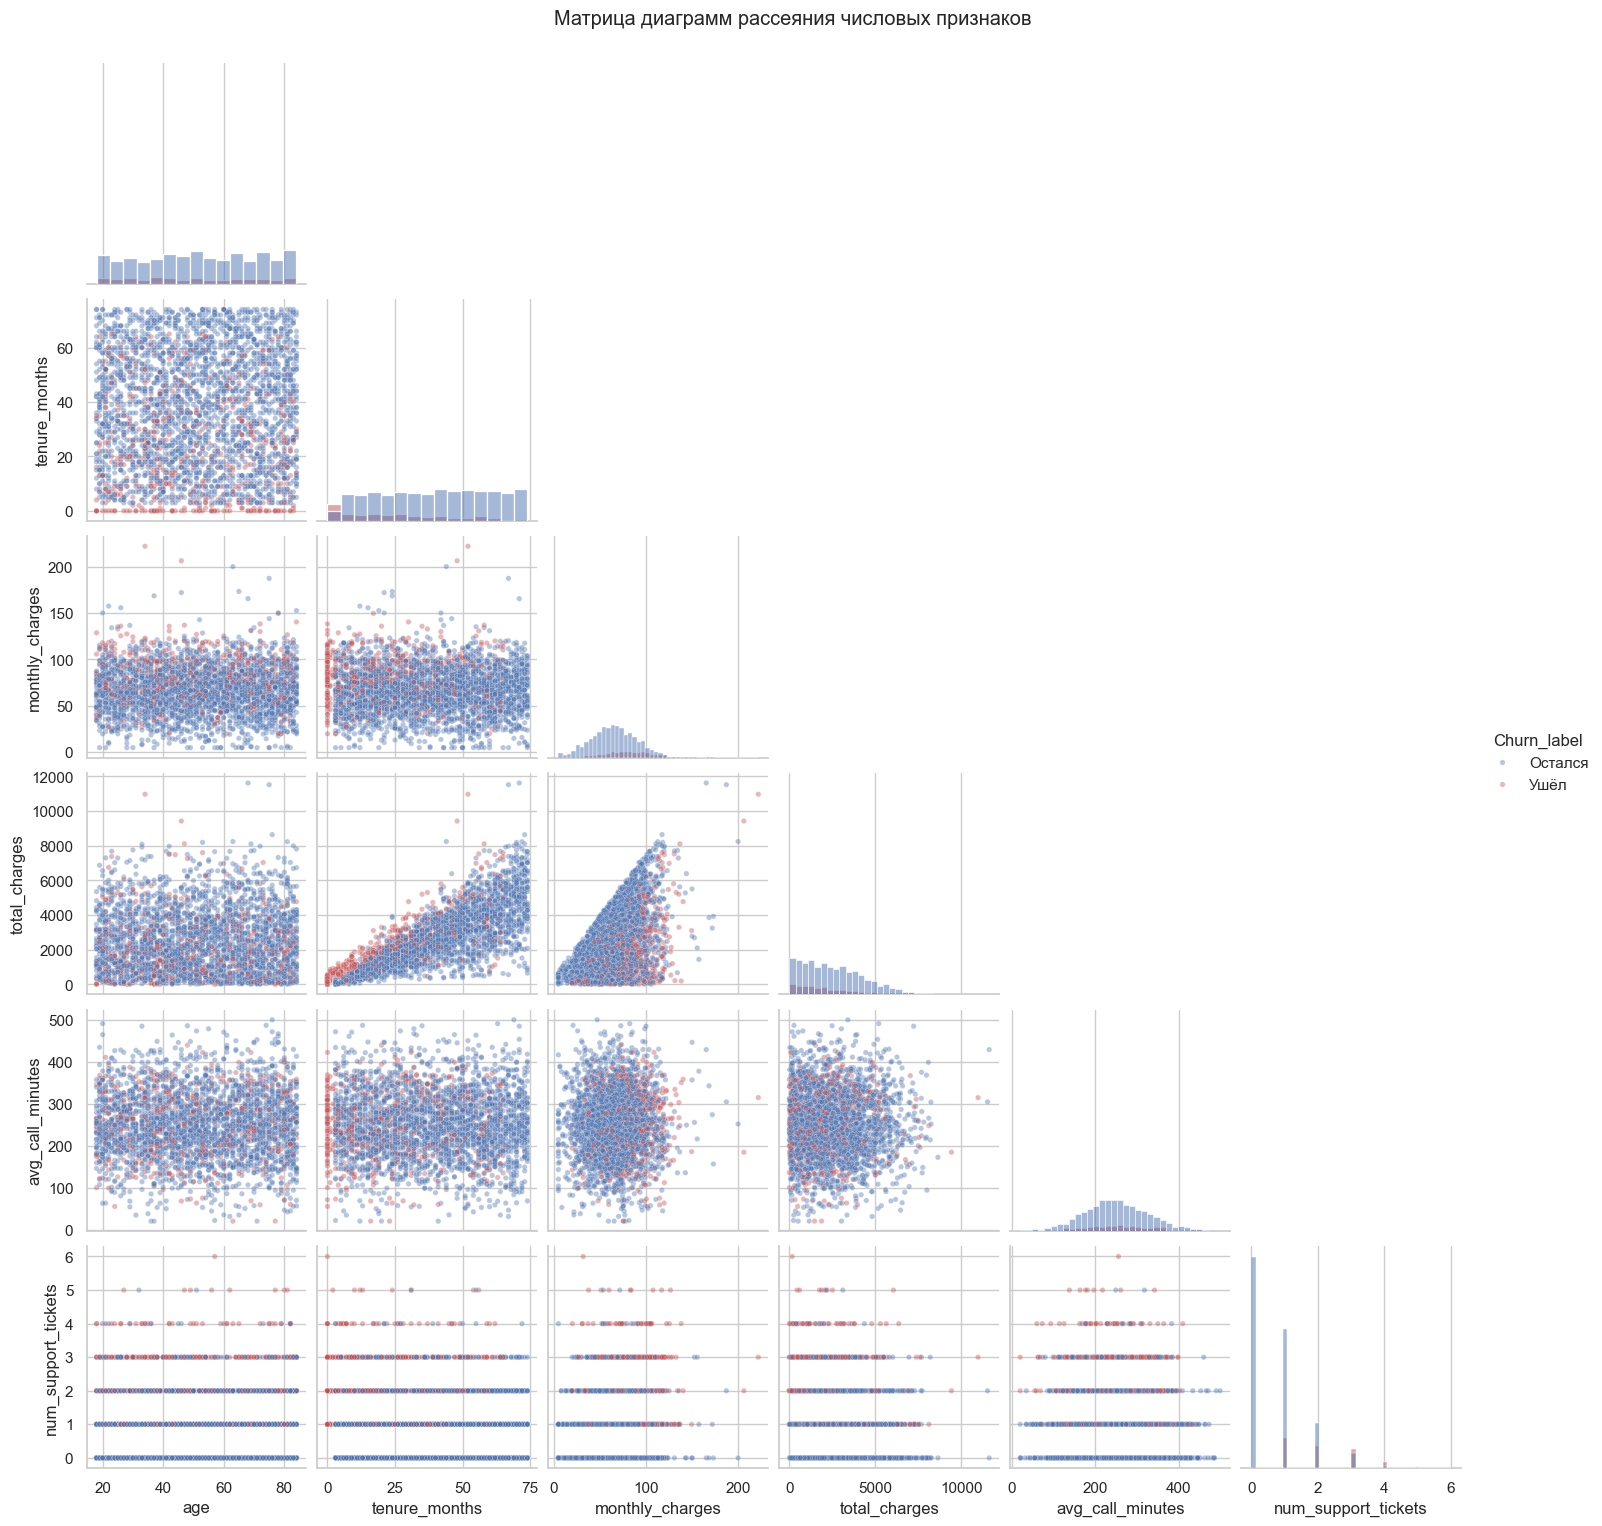

In [31]:
df_model['Churn_label'] = df_model['Churn'].map({0: 'Остался', 1: 'Ушёл'})
pair_cols = num_cols + ['Churn_label']

sns.pairplot(df_model[pair_cols], hue='Churn_label', corner=True,
             diag_kind='hist', plot_kws={'alpha': 0.4, 's': 15},
             palette={'Остался': '#4C72B0', 'Ушёл': '#C44E52'})
plt.suptitle('Матрица диаграмм рассеяния числовых признаков', y=1.02)
plt.show()

**Интерпретация.** На диаграммах рассеяния ушедшие клиенты (`Churn = 1`) заметно концентрируются в области с небольшим стажем `tenure_months`, высокими ежемесячными платежами `monthly_charges` и большим числом обращений в поддержку `num_support_tickets`. Для оставшихся клиентов характерны более длительный стаж и меньшая частота обращений. При этом облака сильно перекрываются, поэтому чёткие линейные границы между классами не выражены, а кластеры не совпадают с `Churn` напрямую. Это ожидаемо: кластеризация ищет группы по сходству признаков, а не по целевой переменной.

## 5. Подбор оптимального числа кластеров

Для выбора числа кластеров использованы метод локтя и коэффициент силуэта. Диапазон k составил от 2 до 10. Дополнительно для k = 2–4 рассчитаны внешние метрики относительно `Churn`, чтобы оценить, насколько кластеры согласуются с фактическим оттоком.

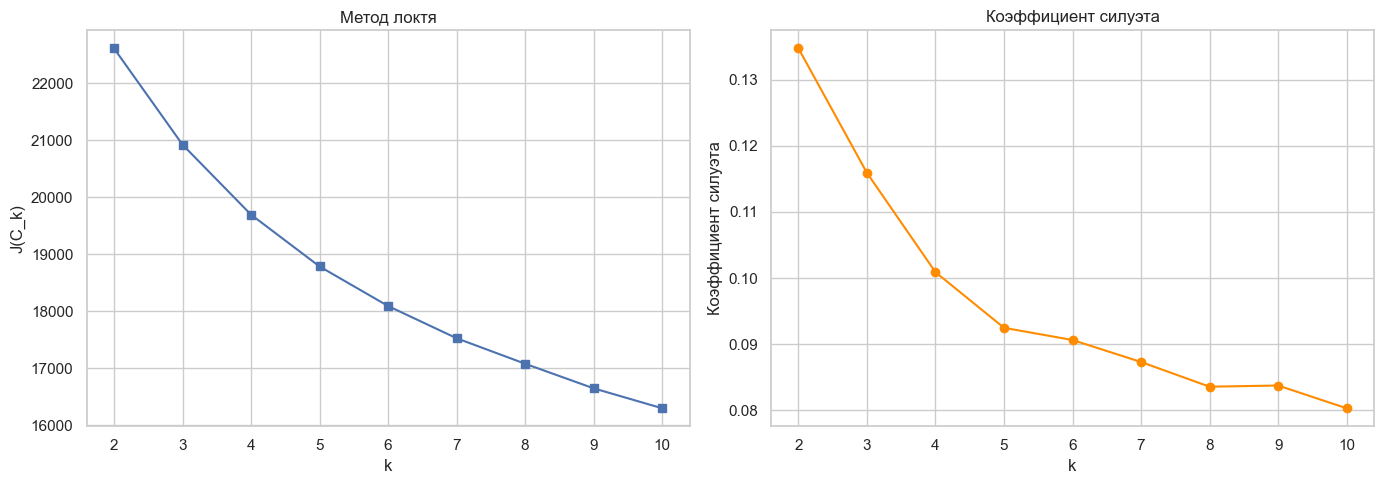

,k,inertia,silhouette
0,2,22608.31,0.1347
1,3,20920.65,0.1159
2,4,19694.12,0.1009
3,5,18786.32,0.0925
4,6,18093.24,0.0906
5,7,17528.52,0.0873
6,8,17081.77,0.0836
7,9,16650.89,0.0838
8,10,16301.64,0.0803


In [32]:
k_values = list(range(2, 11))
elbow = []
sil_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_scaled)
    elbow.append(model.inertia_)
    sil_scores.append(silhouette_score(X_scaled, model.labels_,
                                       sample_size=1200,
                                       random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_values, elbow, marker='s')
axes[0].set_xlabel('k')
axes[0].set_ylabel('J(C_k)')
axes[0].set_title('Метод локтя')
axes[0].set_xticks(k_values)

axes[1].plot(k_values, sil_scores, marker='o', color='darkorange')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Коэффициент силуэта')
axes[1].set_title('Коэффициент силуэта')
axes[1].set_xticks(k_values)
plt.tight_layout()
plt.show()

k_selection = pd.DataFrame({
    'k': k_values,
    'inertia': np.round(elbow, 2),
    'silhouette': np.round(sil_scores, 4)
})
display(k_selection)

In [33]:
external_selection = []
for k in [2, 3, 4]:
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(X_scaled)
    external_selection.append({
        'k': k,
        'ARI': metrics.adjusted_rand_score(y, labels),
        'AMI': metrics.adjusted_mutual_info_score(y, labels),
        'FMI': metrics.fowlkes_mallows_score(y, labels),
        'Homogeneity': metrics.homogeneity_score(y, labels),
        'Completeness': metrics.completeness_score(y, labels),
        'V-measure': metrics.v_measure_score(y, labels),
    })

external_selection_df = pd.DataFrame(external_selection).round(4)
display(external_selection_df)

,k,ARI,AMI,FMI,Homogeneity,Completeness,V-measure
0,2,-0.0047,0.0152,0.6062,0.0199,0.0127,0.0155
1,3,0.1193,0.1273,0.5771,0.2181,0.0902,0.1277
2,4,0.0622,0.0892,0.4836,0.1833,0.0594,0.0897


**Интерпретация.** На графике метода локтя наиболее заметный излом расположен в окрестности k = 3: после этого значения снижение `inertia` замедляется. Коэффициент силуэта формально максимален при k = 2, однако при k = 3 он остаётся положительным и лишь незначительно ниже, а кластеры становятся содержательнее. По совокупности внешних метрик k = 3 выглядит предпочтительнее: ARI, AMI, Homogeneity и V-мера максимальны именно при k = 3, а FMI при k = 2 и k = 3 различаются слабо (0.606 против 0.577). Для дальнейшего анализа выбрано k = 3: оно соответствует излому на кривой локтя и позволяет выделить отдельную группу клиентов с повышенным риском оттока.

## 6. Кластеризация K-means при k = 3

Финальная модель K-means обучена для трёх кластеров. Для интерпретации результатов дополнительно построена диаграмма рассеяния по двум наиболее информативным признакам — стажу обслуживания и ежемесячным платежам. Маркерами показаны средние значения признаков внутри каждого кластера.

Размеры кластеров: {0: 1128, 1: 634, 2: 1254}
Inertia: 20920.65
Число итераций: 23


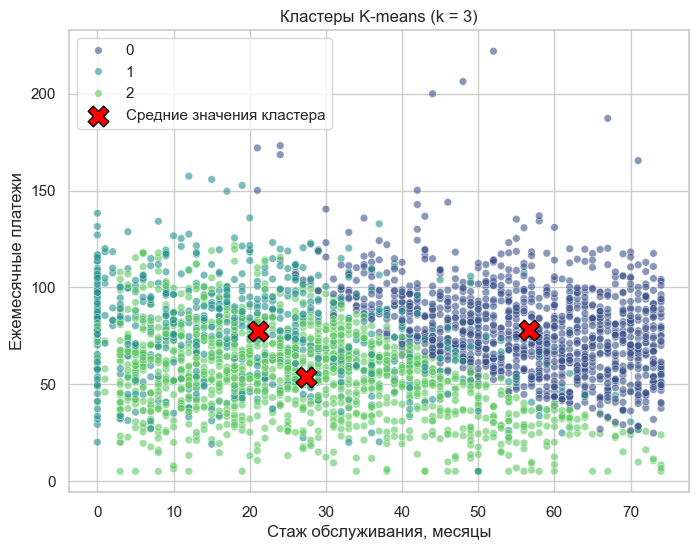

In [34]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
labels_kmeans = kmeans.fit_predict(X_scaled)
df_model['cluster_kmeans'] = labels_kmeans
df_model['cluster_kmeans_str'] = labels_kmeans.astype(str)

print('Размеры кластеров:', {int(k): int(v) for k, v in zip(*np.unique(labels_kmeans, return_counts=True))})
print('Inertia:', round(kmeans.inertia_, 2))
print('Число итераций:', kmeans.n_iter_)

cluster_means = df_model.groupby('cluster_kmeans')[['tenure_months', 'monthly_charges']].mean()

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_model, x='tenure_months', y='monthly_charges',
                hue='cluster_kmeans_str', palette='viridis', alpha=0.6, s=30)
plt.scatter(cluster_means['tenure_months'], cluster_means['monthly_charges'],
            c='red', marker='X', s=220, edgecolor='black',
            label='Средние значения кластера')
plt.xlabel('Стаж обслуживания, месяцы')
plt.ylabel('Ежемесячные платежи')
plt.title('Кластеры K-means (k = 3)')
plt.legend()
plt.show()

**Интерпретация.** На диаграмме выделяются три области. Кластер с наибольшим стажем и высокими платежами расположен в правой верхней части; кластер с небольшим стажем и низкими платежами — в левой нижней; третий кластер объединяет клиентов с небольшим стажем, но высокими платежами. Именно последний кластер визуально наиболее обособлен по оси платежей. Средние значения кластеров (красные маркеры) лежат внутри соответствующих облаков.

## 7. Средние показатели по кластерам

Для содержательной интерпретации рассчитаны размеры кластеров, средние значения числовых признаков и доля ушедших клиентов. Дополнительно для категориальных признаков определена преобладающая категория и её доля внутри кластера.

In [35]:
cluster_profile = df_model.groupby('cluster_kmeans')[num_cols + ['Churn']].mean().round(2)
cluster_profile.insert(0, 'Размер', df_model['cluster_kmeans'].value_counts().sort_index())
display(cluster_profile)

cluster_cat = {}
for cl in sorted(df_model['cluster_kmeans'].unique()):
    subset = df_model[df_model['cluster_kmeans'] == cl]
    row = {}
    for col in cat_cols:
        share = subset[col].value_counts(normalize=True)
        row[col] = f'{share.index[0]} ({share.iloc[0]:.1%})'
    cluster_cat[cl] = row

cluster_cat_df = pd.DataFrame(cluster_cat).T
cluster_cat_df.index.name = 'cluster_kmeans'
display(cluster_cat_df)

,Размер,age,tenure_months,monthly_charges,total_charges,avg_call_minutes,num_support_tickets,Churn
cluster_kmeans,,,,,,,,
0,1128,52.69,56.72,78.04,4357.42,251.29,0.73,0.08
1,634,52.15,21.12,77.70,1606.41,237.37,2.23,0.50
2,1254,50.14,27.34,53.77,1284.00,253.00,0.40,0.06


,gender,contract_type,payment_method,has_international_plan,region
cluster_kmeans,,,,,
0,M (50.6%),Month-to-month (61.1%),Electronic check (43.2%),No (81.6%),South (22.4%)
1,F (52.1%),Month-to-month (86.0%),Electronic check (59.8%),No (79.2%),South (22.1%)
2,F (50.2%),Month-to-month (50.2%),Electronic check (39.4%),No (83.2%),South (23.5%)


**Интерпретация.** Кластер 0 (1128 клиентов) объединяет клиентов с наибольшим стажем (в среднем 56.7 месяца), высокими платежами (`monthly_charges` ≈ 78.0) и накопленными платежами (`total_charges` ≈ 4357). Доля оттока в нём минимальна — около 7.9%. Кластер 2 (1254 клиента) характеризуется средним стажем около 27.3 месяца и самыми низкими ежемесячными платежами (≈ 53.8); доля оттока — около 6.0%. Кластер 1 (634 клиента) имеет небольшой стаж (≈ 21.1 месяца), высокие ежемесячные платежи (≈ 77.7), низкие накопленные платежи (≈ 1606) и наибольшее число обращений в поддержку (≈ 2.23); доля оттока в нём достигает 50.0%. По категориальным признакам во всех кластерах преобладают клиенты без международного плана, однако в кластере 1 заметно выше доля контрактов Month-to-month (86.0%) и оплаты Electronic check (59.8%) по сравнению с кластерами 0 и 2.

## 8. Метрики качества кластеризации K-means

Для выбранного разбиения рассчитаны внутренняя метрика (коэффициент силуэта) и внешние метрики, использующие `Churn` как эталонную разметку.

In [36]:
kmeans_metrics = {
    'Метод': 'K-means (k=3)',
    'Silhouette': silhouette_score(X_scaled, labels_kmeans),
    'ARI': metrics.adjusted_rand_score(y, labels_kmeans),
    'AMI': metrics.adjusted_mutual_info_score(y, labels_kmeans),
    'FMI': metrics.fowlkes_mallows_score(y, labels_kmeans),
    'Homogeneity': metrics.homogeneity_score(y, labels_kmeans),
    'Completeness': metrics.completeness_score(y, labels_kmeans),
    'V-measure': metrics.v_measure_score(y, labels_kmeans),
}
kmeans_metrics_df = pd.DataFrame([kmeans_metrics]).set_index('Метод').round(4)
display(kmeans_metrics_df)

,Silhouette,ARI,AMI,FMI,Homogeneity,Completeness,V-measure
Метод,,,,,,,
K-means (k=3),0.1168,0.1193,0.1273,0.5771,0.2181,0.0902,0.1277


**Интерпретация.** Коэффициент силуэта ≈ 0.117 указывает на умеренную, но положительную компактность кластеров: структура слабее, чем в синтетическом примере, что объясняется перекрытием признаков. Внешние метрики согласованности с `Churn` невысоки: ARI ≈ 0.119, AMI ≈ 0.127, V-мера ≈ 0.128, Homogeneity ≈ 0.218, Completeness ≈ 0.090. Это означает, что кластеры лишь частично совпадают с фактическим оттоком: они отражают общую структуру клиентской базы, а не являются прямым классификатором оттока. Наибольший вклад в согласованность даёт выделение кластера с высокой долей ушедших клиентов.

## 9. Иерархическая агломеративная кластеризация

Агломеративная кластеризация выполнена методом Ward на той же стандартизованной матрице признаков. Дендрограмма построена на полном наборе из 3016 наблюдений; для читаемости на графике показаны последние 30 объединений (`truncate_mode='lastp', p=30`). Итоговое разбиение также получено на полном наборе данных.

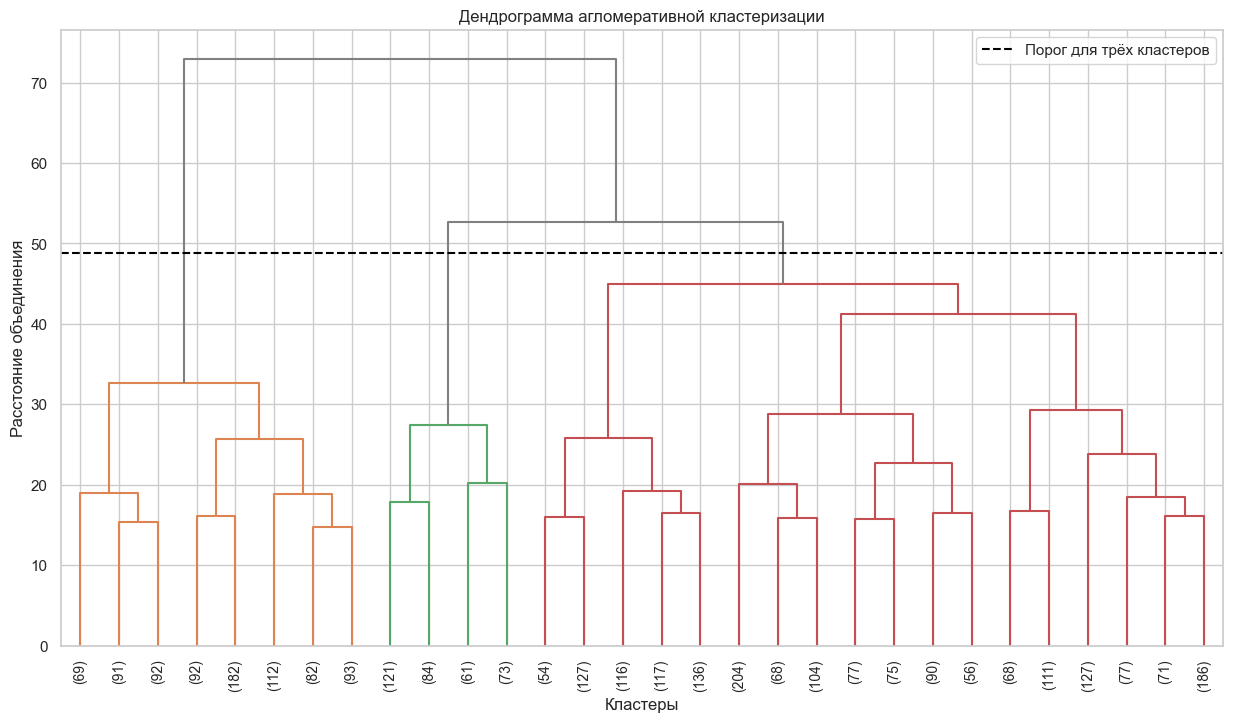

In [37]:
linked = linkage(X_scaled, method='ward')
threshold = (linked[-3, 2] + linked[-2, 2]) / 2

plt.figure(figsize=(15, 8))
dendrogram(linked, truncate_mode='lastp', p=30, leaf_rotation=90,
           leaf_font_size=10, color_threshold=threshold,
           above_threshold_color='gray')
plt.axhline(threshold, color='black', linestyle='--', linewidth=1.5,
            label='Порог для трёх кластеров')
plt.title('Дендрограмма агломеративной кластеризации')
plt.xlabel('Кластеры')
plt.ylabel('Расстояние объединения')
plt.legend()
plt.show()

**Интерпретация.** На дендрограмме, построенной по полному набору, видны три крупные ветви, которые объединяются на заметно большем расстоянии, чем внутренние подкластеры: объединение двух основных ветвей происходит на расстоянии ≈ 73, тогда как последние внутренние объединения — на расстоянии ≈ 45–53. Горизонтальная пунктирная линия, проведённая между уровнями объединения третьего и второго кластеров, отсекает три кластера. Внутри крупных ветвей дальнейшие объединения происходят на существенно меньших расстояниях, что подтверждает выбор k = 3. Наличие трёх основных ветвей согласуется с результатом K-means.

## 10. Результаты агломеративной кластеризации

Итоговое разбиение получено методом Ward для трёх кластеров на полном наборе. Для сравнения с K-means рассчитаны размеры кластеров, средние значения признаков и доля оттока.

In [38]:
agg = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_agg = agg.fit_predict(X_scaled)
df_model['cluster_agg'] = labels_agg

print('Размеры кластеров:', {int(k): int(v) for k, v in zip(*np.unique(labels_agg, return_counts=True))})

agg_profile = df_model.groupby('cluster_agg')[num_cols + ['Churn']].mean().round(2)
agg_profile.insert(0, 'Размер', df_model['cluster_agg'].value_counts().sort_index())
display(agg_profile)

agg_cat = {}
for cl in sorted(df_model['cluster_agg'].unique()):
    subset = df_model[df_model['cluster_agg'] == cl]
    row = {}
    for col in cat_cols:
        share = subset[col].value_counts(normalize=True)
        row[col] = f'{share.index[0]} ({share.iloc[0]:.1%})'
    agg_cat[cl] = row

agg_cat_df = pd.DataFrame(agg_cat).T
agg_cat_df.index.name = 'cluster_agg'
display(agg_cat_df)

Размеры кластеров: {0: 1864, 1: 813, 2: 339}


,Размер,age,tenure_months,monthly_charges,total_charges,avg_call_minutes,num_support_tickets,Churn
cluster_agg,,,,,,,,
0,1864,53.23,30.39,61.40,1713.52,250.89,0.68,0.12
1,813,46.90,56.21,80.07,4475.23,253.23,0.65,0.09
2,339,53.22,27.44,74.27,2098.49,229.10,2.76,0.54


,gender,contract_type,payment_method,has_international_plan,region
cluster_agg,,,,,
0,M (51.4%),Month-to-month (58.9%),Electronic check (42.4%),No (82.2%),South (22.3%)
1,F (57.7%),Month-to-month (55.8%),Electronic check (43.9%),No (79.7%),East (22.5%)
2,M (58.1%),Month-to-month (91.7%),Electronic check (62.8%),No (84.1%),South (27.7%)


**Интерпретация.** Агломеративная кластеризация также выделила три группы. Кластер 1 (813 клиентов) объединяет клиентов с наибольшим стажем (≈ 56.2 месяца) и высокими платежами (≈ 80.1); доля оттока в нём минимальна — около 8.6%. Кластер 2 (339 клиентов) имеет наибольшее число обращений в поддержку (≈ 2.76), небольшой стаж (≈ 27.4 месяца) и высокие платежи (≈ 74.3), а доля оттока в нём достигает 53.7%. Третий, самый крупный кластер (1864 клиента) объединяет клиентов со средним стажем (≈ 30.4 месяца), низкими платежами (≈ 61.4) и долей оттока около 12.3%. По категориальным признакам в кластере с высоким оттоком преобладают контракты Month-to-month (91.7%) и оплата Electronic check (62.8%), что усиливает его отличие от остальных групп.

## 11. Метрики качества агломеративной кластеризации

Для агломеративного разбиения рассчитаны те же метрики, что и для K-means. Сводная таблица позволяет сопоставить методы.

In [39]:
agg_metrics = {
    'Метод': 'Agglomerative (k=3, ward)',
    'Silhouette': silhouette_score(X_scaled, labels_agg),
    'ARI': metrics.adjusted_rand_score(y, labels_agg),
    'AMI': metrics.adjusted_mutual_info_score(y, labels_agg),
    'FMI': metrics.fowlkes_mallows_score(y, labels_agg),
    'Homogeneity': metrics.homogeneity_score(y, labels_agg),
    'Completeness': metrics.completeness_score(y, labels_agg),
    'V-measure': metrics.v_measure_score(y, labels_agg),
}
comparison_metrics = pd.concat([
    kmeans_metrics_df,
    pd.DataFrame([agg_metrics]).set_index('Метод').round(4)
])
display(comparison_metrics)

,Silhouette,ARI,AMI,FMI,Homogeneity,Completeness,V-measure
Метод,,,,,,,
K-means (k=3),0.1168,0.1193,0.1273,0.5771,0.2181,0.0902,0.1277
"Agglomerative (k=3, ward)",0.0829,0.0978,0.0772,0.6277,0.1182,0.0578,0.0777


**Интерпретация.** K-means превосходит агломеративную кластеризацию по коэффициенту силуэта (≈ 0.117 против ≈ 0.083) и по большинству внешних метрик: ARI ≈ 0.119 против ≈ 0.098, AMI ≈ 0.127 против ≈ 0.077, Homogeneity ≈ 0.218 против ≈ 0.118, V-мера ≈ 0.128 против ≈ 0.078. Более высокое значение FMI у агломеративного метода (≈ 0.628 против ≈ 0.577) не компенсирует общего преимущества K-means. Оба метода выделяют схожую группу с повышенным оттоком, но K-means даёт более компактные и лучше согласованные с целевой переменной кластеры.

## 12. Сравнение кластеров K-means и агломеративного метода

Для наглядного сравнения построены две диаграммы рассеяния по стажу и ежемесячным платежам, а также столбчатая диаграмма доли оттока по кластерам каждого метода.

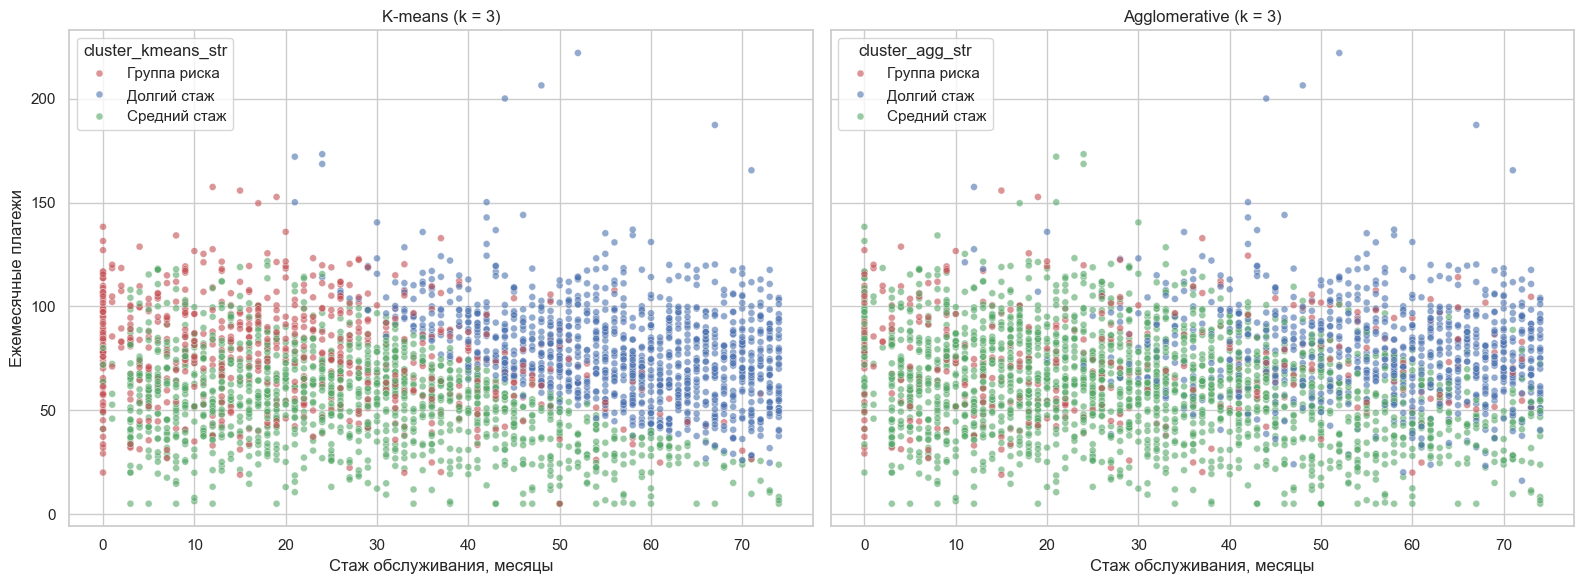

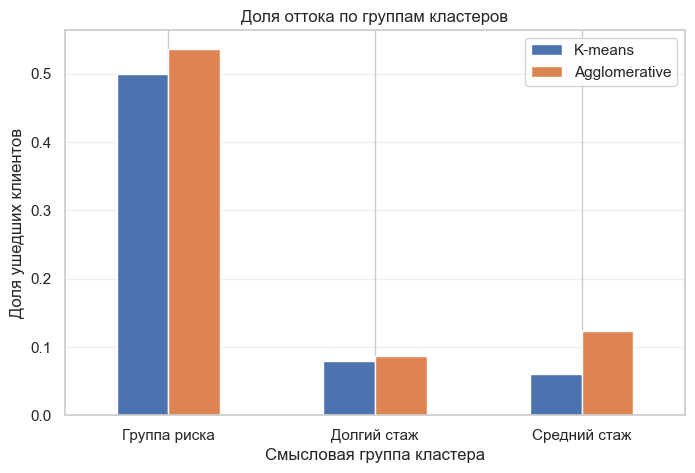

,K-means,Agglomerative
Группа риска,0.5000,0.5369
Долгий стаж,0.0789,0.0861
Средний стаж,0.0598,0.1229


In [40]:
def role_labels(labels, data):
    stats = data.groupby(labels)[['tenure_months', 'Churn']].mean()
    risk = stats['Churn'].idxmax()
    rest = stats.drop(index=risk)
    long_tenure = rest['tenure_months'].idxmax()
    mid_tenure = rest.drop(index=long_tenure).index[0]
    return {risk: 'Группа риска',
            long_tenure: 'Долгий стаж',
            mid_tenure: 'Средний стаж'}


role_kmeans = role_labels(df_model['cluster_kmeans'], df_model)
role_agg = role_labels(df_model['cluster_agg'], df_model)

df_model['cluster_kmeans_str'] = df_model['cluster_kmeans'].map(role_kmeans)
df_model['cluster_agg_str'] = df_model['cluster_agg'].map(role_agg)

role_palette = {'Группа риска': '#C44E52',
                'Долгий стаж': '#4C72B0',
                'Средний стаж': '#55A868'}

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharex=True, sharey=True)
for ax, (col, title) in zip(axes, [('cluster_kmeans_str', 'K-means (k = 3)'),
                                   ('cluster_agg_str', 'Agglomerative (k = 3)')]):
    sns.scatterplot(data=df_model, x='tenure_months', y='monthly_charges',
                    hue=col, palette=role_palette, hue_order=list(role_palette),
                    alpha=0.6, s=25, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('Стаж обслуживания, месяцы')
    ax.set_ylabel('Ежемесячные платежи')
plt.tight_layout()
plt.show()

role_order = ['Группа риска', 'Долгий стаж', 'Средний стаж']
churn_by_cluster = pd.DataFrame({
    'K-means': df_model.groupby('cluster_kmeans_str')['Churn'].mean(),
    'Agglomerative': df_model.groupby('cluster_agg_str')['Churn'].mean(),
}).reindex(role_order)

churn_by_cluster.plot(kind='bar', figsize=(8, 5), color=['#4C72B0', '#DD8452'])
plt.ylabel('Доля ушедших клиентов')
plt.xlabel('Смысловая группа кластера')
plt.title('Доля оттока по группам кластеров')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()
display(churn_by_cluster.round(4))

**Интерпретация.** На диаграммах видно, что оба метода выделяют компактную группу клиентов с небольшим стажем и высокими платежами. Поскольку нумерация кластеров у K-means и Ward независима, для сравнения кластеры переименованы по смыслу («Группа риска», «Долгий стаж», «Средний стаж»); поэтому высокие столбцы обоих методов теперь стоят в одной категории. Границы кластеров K-means выглядят более чёткими, а агломеративный метод относит к группе риска меньше клиентов (339 против 634), из-за чего доля оттока в ней выше (53.7% против 50.0%). Столбчатая диаграмма подтверждает, что оба метода формируют один кластер с долей оттока около 50%, тогда как остальные группы имеют долю около 6–12%. Это означает, что оба метода обнаруживают одну и ту же группу риска, но K-means охватывает её шире.

## 13. Выводы по Части 2

Набор `telecom_churn.csv` содержит 3016 клиентов и 12 признаков; пропусков и полных дубликатов нет, доля оттока составляет около 15.9%. После пересчёта 26 отрицательных значений `total_charges` как `monthly_charges × tenure_months`, прямого кодирования категориальных признаков и стандартизации числовых признаков была получена матрица из 22 столбцов. Целевая переменная `Churn` в модель не включалась.

Для выбора числа кластеров использованы метод локтя и коэффициент силуэта. Метод локтя указывает на k = 3: после этого значения снижение суммы квадратов расстояний замедляется. Коэффициент силуэта формально максимален при k = 2, однако при k = 3 он остаётся положительным, а внешние метрики согласованности с `Churn` (ARI, AMI, Homogeneity, V-мера) заметно выше. Поэтому для содержательного анализа выбрано k = 3.

Кластеризация K-means при k = 3 выделила три группы. Первая группа (1128 клиентов) характеризуется наибольшим стажем, высокими платежами и минимальной долей оттока около 7.9%. Вторая группа (1254 клиента) имеет средний стаж и самые низкие ежемесячные платежи, доля оттока в ней около 6.0%. Третья группа (634 клиента) объединяет клиентов с небольшим стажем, высокими ежемесячными платежами, низкими накопленными платежами и большим числом обращений в поддержку; доля оттока в ней достигает 50.0%, а среди категориальных признаков преобладают контракты Month-to-month (86.0%) и оплата Electronic check (59.8%). Эта группа является основной группой риска.

Агломеративная кластеризация методом Ward при k = 3 дала схожую картину: выделена группа с наибольшим числом обращений в поддержку и долей оттока 53.7%, а также группа с наибольшим стажем и минимальным оттоком 8.6%. Однако K-means превзошёл агломеративный метод по коэффициенту силуэта (≈ 0.117 против ≈ 0.083), ARI (≈ 0.119 против ≈ 0.098), AMI (≈ 0.127 против ≈ 0.077), Homogeneity (≈ 0.218 против ≈ 0.118) и V-мере (≈ 0.128 против ≈ 0.078). Более высокое значение FMI у агломеративного метода (≈ 0.628 против ≈ 0.577) не меняет общего вывода.

Метрики согласованности с `Churn` остаются умеренными: кластеры отражают структуру клиентской базы по стажу, платежам и обращениям в поддержку, но не заменяют модель классификации оттока. Наиболее информативным результатом является выделение компактной группы клиентов с коротким стажем, высокими платежами и высокой нагрузкой на поддержку, в которой доля оттока примерно в три раза выше средней по выборке.

# Общий вывод по работе

В ходе лабораторной работы были изучены и практически применены методы кластеризации: K-means и агломеративная иерархическая кластеризация. Отдельное внимание уделено внутренним и внешним метрикам качества, выбору оптимального числа кластеров и содержательной интерпретации полученных групп.

В Части 1 на синтетическом наборе из трёх групп метод K-means при k = 3 восстановил исходную структуру данных: коэффициент силуэта составил ≈ 0.719, центры кластеров совпали с центрами облаков, а метод локтя подтвердил выбор трёх кластеров. При k = 2 две группы объединялись, при k = 4 одна из групп дробилась, что сопровождалось снижением коэффициента силуэта. Этот пример показал, что при явно выраженной структуре данных внутренние метрики и визуальный анализ дают согласованный результат.

В Части 2 на наборе `telecom_churn.csv` было реализовано полное исследование: пересчёт отрицательных значений `total_charges` как `monthly_charges × tenure_months`, прямое кодирование категориальных признаков и стандартизация числовых признаков. Целевая переменная `Churn` в модель не включалась и использовалась только для оценки качества кластеризации. Метод локтя указал на k = 3, а коэффициент силуэта формально был максимален при k = 2. Для дальнейшего анализа выбрано k = 3, поскольку при этом разбиении внешние метрики согласованности с `Churn` были выше, а кластеры имели содержательную интерпретацию.

Кластеризация K-means при k = 3 выделила три группы клиентов. Наиболее важной оказалась группа из 634 клиентов с небольшим стажем, высокими ежемесячными платежами, низкими накопленными платежами и большим числом обращений в поддержку: доля оттока в ней составила 50.0% против 15.9% в среднем по выборке. Две другие группы имели долю оттока около 6–8% и различались стажем и уровнем платежей. Агломеративная кластеризация методом Ward выделила аналогичную группу риска с долей оттока 53.7%, однако уступила K-means по коэффициенту силуэта и большинству внешних метрик.

По результатам работы можно сделать вывод, что для данного набора данных целесообразнее использовать K-means: он даёт более компактные кластеры, лучше согласуется с целевой переменной и требует меньше вычислительных ресурсов. Агломеративная кластеризация полезна для визуального анализа иерархической структуры, но на полном наборе из 3016 объектов она уступает по коэффициенту силуэта и сильнее зависит от выбора метода связи. При этом ни один из методов не заменяет модель классификации оттока: кластеры описывают структуру клиентской базы, а не прогнозируют уход клиента. Основным практическим результатом является выделение группы клиентов с коротким стажем, высокими платежами и повышенной нагрузкой на поддержку, для которой целесообразно разработать отдельные удерживающие мероприятия.

Ограничением работы является использование одного случайного состояния для K-means, а также прямое кодирование категориальных признаков без дополнительного отбора. Отдельно стоит отметить чувствительность агломеративной кластеризации к предобработке: замена 26 отрицательных значений `total_charges` формулой вместо медианы изменила состав крупных кластеров Ward (ARI между вариантами ≈ 0.41), тогда как разбиение K-means осталось практически прежним (ARI ≈ 0.96). При слабой разделимости данных (коэффициент силуэта ≈ 0.08) иерархический метод менее устойчив, поэтому его результаты следует интерпретировать с осторожностью. Для более надёжных выводов целесообразно проверить устойчивость кластеров на нескольких запусках, сравнить различные методы связи и рассмотреть альтернативные метрики расстояния для смешанных признаков.